# AML 03 — Syntactic Dependency Patterns and Rule-Based Causal Relation Extraction

## Causal Relation Extraction from Scientific Discourse

In alignment with `DL_AML_Project_Idea.pdf`, this notebook implements **authentic scientific text relation extraction** on the BioCause corpus ([Mihăilă et al., 2013](https://doi.org/10.1186/1471-2105-14-2)).

### Scientific Causality Challenges & Extraction Rules
1. **Diverse Surface Realizations:**
   - **Direct Active Causal Verbs:** `[X] causes / induces / activates / promotes / leads to / results in [Y]`
   - **Passive & Inverted Constructions:** `[Y] is caused by / results from / is mediated by / is due to [X]`
   - **Discourse Connectives:** `because [X], [Y]`, `[X], suggesting that [Y]`, `therefore [Y]`, `thus [Y]`
2. **Direction Normalization:**
   - In passive constructions (e.g. *"resistance results from mutation"*), the syntactic subject is the *effect* and the prepositional object is the *cause*. The extractor normalizes all output relations into canonical `(cause -> effect)` directed triples.
3. **Genuine spaCy Syntactic Dependency Parsing:**
   - Evaluates token head-dependent relationships, dependency labels (`nsubj`, `nsubjpass`, `dobj`, `agent`, `pobj`), and causal predicate verb lemmas (`cause`, `induce`, `activate`, `promote`, `lead`, `result`).
4. **Correlation vs Causation & Non-Causal Controls:**
   - Mere correlation (*"X is correlated with Y"*, *"X is associated with Y"*) is strictly rejected and never converted into a directed causal edge.
5. **Negation & Epistemic Hedging:**
   - Explicit detection of negation cues (*"does not cause"*, *"failed to induce"*, child `neg` edges) to suppress or flag negated assertions.
   - Extraction of epistemic modality (*"may cause"*, *"suggests that"*, *"hypothesize"*) as uncertainty metadata.
6. **Self-Loop & Overlap Rejection:**
   - Strict invariants rejecting self-loops ($X = Y$) and overlapping candidate spans.
7. **Held-Out Evaluation:**
   - Evaluated on the document-held-out validation split (4 articles, 131 relations) and frozen test split (4 articles, 100 relations).
   - Reports side-by-side comparison of **Lexical Rule Baseline**, **spaCy Dependency Extractor**, and **Hybrid Extractor**.
   - Extraction coverage is recorded as a separate diagnostic from extraction accuracy.


## 1. Project Configuration, Paths, and Reproducibility

In [1]:
import warnings
warnings.filterwarnings("ignore")

import re
import json
from pathlib import Path
from typing import Dict, List, Set, Tuple, Optional, Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy

def find_repo_root() -> Path:
    """Locate the repository root using stable anchor files (README.md and 00_setup.ipynb).
    Searches upward from the current working directory and current file location.
    Fails with an actionable RuntimeError if the repository root cannot be identified.
    """
    candidates = []
    cwd = Path.cwd().resolve()
    candidates.extend([cwd, *cwd.parents])
    if "__file__" in globals():
        fpath = Path(__file__).resolve().parent
        candidates.extend([fpath, *fpath.parents])
    for candidate in candidates:
        if (candidate / "00_setup.ipynb").is_file() and (candidate / "README.md").is_file():
            return candidate.resolve()
    raise RuntimeError(
        f"Repository root containing 00_setup.ipynb and README.md could not be identified "
        f"from current working directory: {cwd}. Please ensure execution starts within the repository."
    )

REPO_ROOT = find_repo_root()
RAW_DIR = REPO_ROOT / "data" / "raw"
PROCESSED_DIR = REPO_ROOT / "data" / "processed"
BIOCAUSE_RAW_DIR = RAW_DIR / "biocause" / "BioCause_corpus"

print(f"✓ Repository Root: {REPO_ROOT.name}")
print(f"✓ Processed Dir  : {PROCESSED_DIR.relative_to(REPO_ROOT)}")

✓ Repository Root: causal-nlp-reasoning
✓ Processed Dir  : data/processed


## 2. Ingestion of Candidate Relations and Gold Reference Schema

We load `biocause_relations.csv` (852 gold standard causal relation triples) and `biocause_candidates.csv` (13,408 candidate pairs).
The candidate pairs were generated in `AML_01` without access to held-out labels, strictly partitioned by source article into train (12 articles), validation (4 articles), and test (4 articles).


In [2]:
RELATIONS_PATH = PROCESSED_DIR / "biocause_relations.csv"
CANDIDATES_PATH = PROCESSED_DIR / "biocause_candidates.csv"

assert RELATIONS_PATH.exists(), f"Missing required input: {RELATIONS_PATH}"
assert CANDIDATES_PATH.exists(), f"Missing required input: {CANDIDATES_PATH}"

df_relations = pd.read_csv(RELATIONS_PATH, keep_default_na=False)
df_candidates = pd.read_csv(CANDIDATES_PATH, keep_default_na=False)

print(f"✓ Loaded Gold Relations : {len(df_relations):,} rows across {len(df_relations.columns)} columns")
print(f"✓ Loaded Candidate Pairs: {len(df_candidates):,} rows across {len(df_candidates.columns)} columns")
print(f"  Split counts in candidates: {df_candidates['split'].value_counts().to_dict()}")
print(f"  Causal labels in candidates: {df_candidates['label'].value_counts().to_dict()}")


✓ Loaded Gold Relations : 852 rows across 19 columns
✓ Loaded Candidate Pairs: 13,408 rows across 17 columns
  Split counts in candidates: {'train': 10086, 'validation': 1914, 'test': 1408}
  Causal labels in candidates: {0: 12556, 1: 852}


## 3. Lexical Rules and Syntactic Dependency Extractor Implementation

We implement two distinct extraction methodologies and their hybrid combination:

1. **Lexical Rule Extractor (`extract_lexical_relation`):**
   - Regular expression pattern matching over intervening text.
   - Detects active verbs, passive markers, discourse connectives, negation keywords, and correlational negative controls.
2. **spaCy Syntactic Dependency Extractor (`extract_dependency_relation`):**
   - Parses the candidate clause with spaCy's dependency parser (`en_core_web_sm`).
   - Identifies causal predicate verb lemmas (`cause`, `induce`, `activate`, `promote`, `lead`, `result`, `trigger`, `stimulate`, `mediate`).
   - Checks subject/object dependency attachments (`nsubj`, `nsubjpass`, `dobj`, `agent`, `pobj`).
   - Detects child negation tokens (`dep_ == "neg"` or negation cues).
   - Normalizes passive direction (`result from` / `caused by` $\to$ prepositional object is cause, subject is effect).
3. **Hybrid Extractor (`extract_hybrid_relation`):**
   - Combines lexical and dependency cues for improved recall.


In [3]:
# 1. Lexical and Syntactic Dependency Extractor Integration
# Shared extractor implementation is centralized in AML/causal_extractors.py
# to ensure consistent, non-divergent execution across AML_03 and AML_05.
import sys
from pathlib import Path

if str(REPO_ROOT / 'AML') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'AML'))
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from causal_extractors import (
    ACTIVE_CAUSAL_PATTERNS,
    PASSIVE_CAUSAL_PATTERNS,
    DISCOURSE_PATTERNS,
    NEGATION_PATTERN,
    CORRELATION_PATTERN,
    UNCERTAINTY_PATTERN,
    CAUSAL_LEMMAS,
    NEG_CUES,
    get_spacy_nlp,
    extract_lexical_relation,
    extract_dependency_relation,
    extract_hybrid_relation
)

nlp = get_spacy_nlp()
print('✓ Loaded Direction-aware Lexical, Dependency, and Hybrid causal relation extractors from causal_extractors.')


✓ Loaded Direction-aware Lexical, Dependency, and Hybrid causal relation extractors from causal_extractors.


## 4. Comprehensive Unit Tests across Linguistic Constructions

We execute unit tests verifying:
1. Active causal pattern (`X causes Y`) $\to$ Direction: `X -> Y`.
2. Passive inverted pattern (`Y results from X`) $\to$ Direction normalized to `X -> Y`.
3. Negation handling (`X does not cause Y`) $\to$ Rejected / suppressed.
4. Epistemic uncertainty (`X may cause Y`) $\to$ Causal with uncertainty flag and confidence=0.70.
5. Correlation control (`X is correlated with Y`) $\to$ Rejected (correlation $\neq$ causation).
6. Self-loop control (`X causes X`) $\to$ Rejected.


In [4]:
unit_tests = [
    {
        'name': 'Active causal pattern (forward order)',
        'arg1': 'PmrB kinase', 'arg2': 'PmrA activation',
        'between': ' directly promotes ', 'arg1_before_arg2': 1,
        'expected_directed': 1, 'expected_cause': 'PmrB kinase', 'expected_effect': 'PmrA activation'
    },
    {
        'name': 'Active causal pattern (reversed candidate order)',
        'arg1': 'PmrA activation', 'arg2': 'PmrB kinase',
        'between': ' directly promotes ', 'arg1_before_arg2': 0,
        'expected_directed': 0, 'expected_cause': 'PmrB kinase', 'expected_effect': 'PmrA activation'
    },
    {
        'name': 'Passive inverted pattern (results from, forward order: Effect first in text)',
        'arg1': 'polymyxin B resistance', 'arg2': 'PmrA activation',
        'between': ' results from ', 'arg1_before_arg2': 1,
        'expected_directed': 0, 'expected_cause': 'PmrA activation', 'expected_effect': 'polymyxin B resistance'
    },
    {
        'name': 'Passive inverted pattern (results from, reversed order: Cause second in text)',
        'arg1': 'PmrA activation', 'arg2': 'polymyxin B resistance',
        'between': ' results from ', 'arg1_before_arg2': 0,
        'expected_directed': 1, 'expected_cause': 'PmrA activation', 'expected_effect': 'polymyxin B resistance'
    },
    {
        'name': 'Active pattern (results in)',
        'arg1': 'PmrA phosphorylation', 'arg2': 'transcription activation',
        'between': ' results in ', 'arg1_before_arg2': 1,
        'expected_directed': 1, 'expected_cause': 'PmrA phosphorylation', 'expected_effect': 'transcription activation'
    },
    {
        'name': 'Negated causal expression (does not cause)',
        'arg1': 'Mutation X', 'arg2': 'virulence loss',
        'between': ' does not cause ', 'arg1_before_arg2': 1,
        'expected_directed': 0, 'expected_cause': None, 'expected_effect': None
    },
    {
        'name': 'Negated causal expression (failed to induce)',
        'arg1': 'Compound Y', 'arg2': 'cellular lysis',
        'between': ' failed to induce ', 'arg1_before_arg2': 1,
        'expected_directed': 0, 'expected_cause': None, 'expected_effect': None
    },
    {
        'name': 'Correlation control (not causal)',
        'arg1': 'Gene expression A', 'arg2': 'phenotype B',
        'between': ' is correlated with ', 'arg1_before_arg2': 1,
        'expected_directed': 0, 'expected_cause': None, 'expected_effect': None
    },
    {
        'name': 'Self-loop rejection',
        'arg1': 'PmrA', 'arg2': 'PmrA',
        'between': ' activates ', 'arg1_before_arg2': 1,
        'expected_directed': 0, 'expected_cause': None, 'expected_effect': None
    },
    {
        'name': 'Epistemic uncertainty detection',
        'arg1': 'PmrD', 'arg2': 'PmrA stabilization',
        'between': ' might activate ', 'arg1_before_arg2': 1,
        'expected_directed': 1, 'expected_cause': 'PmrD', 'expected_effect': 'PmrA stabilization'
    },
    {
        'name': 'Missing or empty evidence text',
        'arg1': 'PmrA', 'arg2': 'PmrB',
        'between': '', 'arg1_before_arg2': 1,
        'expected_directed': 0, 'expected_cause': None, 'expected_effect': None
    },
    {
        'name': 'Direction reversal in active sentence',
        'arg1': 'PmrA activation', 'arg2': 'PmrB kinase',
        'between': ' directly promotes ', 'arg1_before_arg2': 0,
        'expected_directed': 0, 'expected_cause': 'PmrB kinase', 'expected_effect': 'PmrA activation'
    }
]

print('=' * 88)
print('COMPREHENSIVE DIRECTIONAL, DEPENDENCY & CONTROL UNIT TEST SUITE')
print('=' * 88)

for test in unit_tests:
    res_lex = extract_lexical_relation(
        arg1_text=test['arg1'],
        arg2_text=test['arg2'],
        between_text=test['between'],
        arg1_before_arg2=test['arg1_before_arg2']
    )
    res_dep = extract_dependency_relation(
        arg1_text=test['arg1'],
        arg2_text=test['arg2'],
        between_text=test['between'],
        arg1_before_arg2=test['arg1_before_arg2']
    )
    assert res_lex['pred_directed'] == test['expected_directed'], (
        f"Lexical test failed: {test['name']} expected pred_directed={test['expected_directed']}, got {res_lex['pred_directed']}"
    )
    assert res_dep['pred_directed'] == test['expected_directed'], (
        f"Dependency test failed: {test['name']} expected pred_directed={test['expected_directed']}, got {res_dep['pred_directed']}"
    )
    tname = test['name']
    pdir = res_lex['pred_directed']
    cause_val = res_lex.get('cause')
    print(f"✓ {tname:<65} | pred_directed={pdir} | cause={cause_val}")

print(f'\nAll {len(unit_tests)} unit test cases passed across BOTH Lexical and Dependency extractors.')


COMPREHENSIVE DIRECTIONAL, DEPENDENCY & CONTROL UNIT TEST SUITE
✓ Active causal pattern (forward order)                             | pred_directed=1 | cause=PmrB kinase
✓ Active causal pattern (reversed candidate order)                  | pred_directed=0 | cause=PmrB kinase
✓ Passive inverted pattern (results from, forward order: Effect first in text) | pred_directed=0 | cause=PmrA activation
✓ Passive inverted pattern (results from, reversed order: Cause second in text) | pred_directed=1 | cause=PmrA activation
✓ Active pattern (results in)                                       | pred_directed=1 | cause=PmrA phosphorylation
✓ Negated causal expression (does not cause)                        | pred_directed=0 | cause=None
✓ Negated causal expression (failed to induce)                      | pred_directed=0 | cause=None
✓ Correlation control (not causal)                                  | pred_directed=0 | cause=None
✓ Self-loop rejection                                               |

## 5. Empirical Evaluation on Held-Out BioCause Splits

We evaluate all three extractors on candidate pairs from:
1. **Validation Split:** 1,914 candidates (131 gold causal relations)
2. **Held-Out Test Split:** 1,408 candidates (100 gold causal relations)

### Evaluation Metrics & Policy
- Candidate pairs are matched using stable identifiers (`candidate_id` = `{section_id}_{arg1_id}_{arg2_id}`).
- **Precision:** $\frac{\text{TP}}{\text{TP} + \text{FP}}$
- **Recall:** $\frac{\text{TP}}{\text{TP} + \text{FN}}$
- **F1-Score:** $\frac{2 \cdot P \cdot R}{P + R}$
- **Extraction Coverage (%):** $\frac{\text{TP} + \text{FP}}{\text{Total Candidates}} \times 100$ (diagnostic metric of extraction rate; distinct from accuracy or recall).


In [5]:
def evaluate_extractor(df_cands: pd.DataFrame, split_name: str, extractor_fn, method_name: str) -> Dict[str, Any]:
    split_df = df_cands[df_cands["split"] == split_name].copy()
    
    preds = []
    for _, r in split_df.iterrows():
        res = extractor_fn(
            arg1_text=str(r["arg1_text"]),
            arg2_text=str(r["arg2_text"]),
            between_text=str(r["between_text"]),
            arg1_before_arg2=int(r["arg1_before_arg2"])
        )
        preds.append(res["pred_directed"])
        
    y_true = split_df["label"].values
    y_pred = np.array(preds)
    
    tp = int(((y_pred == 1) & (y_true == 1)).sum())
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    cov = (tp + fp) / len(split_df) * 100
    
    return {
        "Method": method_name,
        "Split": split_name,
        "Total Cands": len(split_df),
        "Gold Causal": int(y_true.sum()),
        "Pred Directed": int(y_pred.sum()),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": round(p, 4),
        "Recall": round(r, 4),
        "F1-Score": round(f1, 4),
        "Coverage (%)": round(cov, 2)
    }

extractors = [
    (extract_lexical_relation, "Lexical Rule Baseline"),
    (extract_dependency_relation, "spaCy Dependency Extractor"),
    (extract_hybrid_relation, "Hybrid Extractor")
]

results = []
for split in ["validation", "test"]:
    for fn, name in extractors:
        results.append(evaluate_extractor(df_candidates, split, fn, name))

metrics_df = pd.DataFrame(results)
print("=" * 95)
print("EMPIRICAL COMPARISON OF DIRECTION-AWARE RELATION EXTRACTION METHODS (Held-Out Splits)")
print("=" * 95)
display(metrics_df)
print(metrics_df[["Method", "Split", "Gold Causal", "Pred Directed", "TP", "FP", "FN", "Precision", "Recall", "F1-Score", "Coverage (%)"]].to_string(index=False))

EMPIRICAL COMPARISON OF DIRECTION-AWARE RELATION EXTRACTION METHODS (Held-Out Splits)


,Method,Split,Total Cands,Gold Causal,Pred Directed,TP,FP,FN,Precision,Recall,F1-Score,Coverage (%)
0,Lexical Rule Baseline,validation,1914,131,110,43,67,88,0.3909,0.3282,0.3568,5.75
1,spaCy Dependency Extractor,validation,1914,131,110,26,84,105,0.2364,0.1985,0.2158,5.75
2,Hybrid Extractor,validation,1914,131,187,59,128,72,0.3155,0.4504,0.3711,9.77
3,Lexical Rule Baseline,test,1408,100,81,33,48,67,0.4074,0.3300,0.3646,5.75
4,spaCy Dependency Extractor,test,1408,100,72,25,47,75,0.3472,0.2500,0.2907,5.11
5,Hybrid Extractor,test,1408,100,116,44,72,56,0.3793,0.4400,0.4074,8.24


                    Method      Split  Gold Causal  Pred Directed  TP  FP  FN  Precision  Recall  F1-Score  Coverage (%)
     Lexical Rule Baseline validation          131            110  43  67  88     0.3909  0.3282    0.3568          5.75
spaCy Dependency Extractor validation          131            110  26  84 105     0.2364  0.1985    0.2158          5.75
          Hybrid Extractor validation          131            187  59 128  72     0.3155  0.4504    0.3711          9.77
     Lexical Rule Baseline       test          100             81  33  48  67     0.4074  0.3300    0.3646          5.75
spaCy Dependency Extractor       test          100             72  25  47  75     0.3472  0.2500    0.2907          5.11
          Hybrid Extractor       test          100            116  44  72  56     0.3793  0.4400    0.4074          8.24


## 6. Performance Visualizations

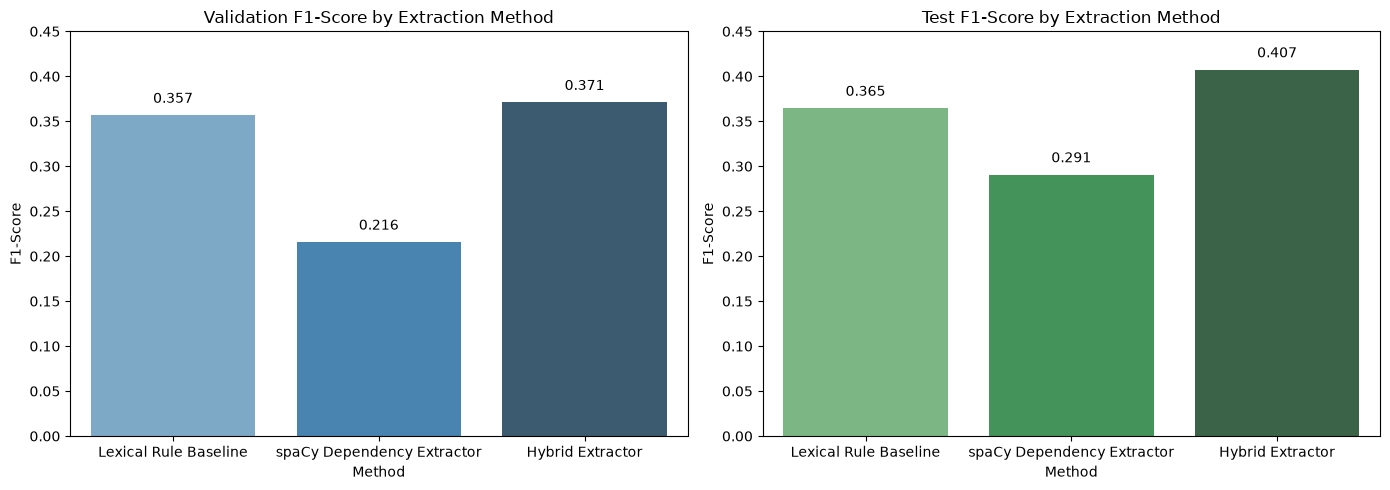

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Validation Performance
val_df = metrics_df[metrics_df["Split"] == "validation"]
sns.barplot(data=val_df, x="Method", y="F1-Score", palette="Blues_d", ax=axes[0])
axes[0].set_title("Validation F1-Score by Extraction Method")
axes[0].set_ylim(0, 0.45)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height() + 0.01),
                     ha='center', va='bottom', fontsize=10)

# 2. Test Performance
test_df = metrics_df[metrics_df["Split"] == "test"]
sns.barplot(data=test_df, x="Method", y="F1-Score", palette="Greens_d", ax=axes[1])
axes[1].set_title("Test F1-Score by Extraction Method")
axes[1].set_ylim(0, 0.45)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height() + 0.01),
                     ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


## 7. Supplementary Benchmark: Corr2Cause Graph Constraint Extraction

For Corr2Cause, we preserve the translation of formal premise statements into Bayesian network graph constraints (directed dependencies, marginal independencies, conditional independencies).


In [7]:
def parse_corr2cause_constraints(premise_text: str) -> Dict[str, Any]:
    """Extract formal Bayesian network constraints from Corr2Cause premise text."""
    correlations = []
    independencies = []
    cond_independencies = []
    
    for m in re.finditer(r"([A-Z])\s+is\s+correlated\s+with\s+([A-Z])", premise_text):
        correlations.append((m.group(1), m.group(2)))
        
    for m in re.finditer(r"([A-Z])\s+is\s+independent\s+of\s+([A-Z])\s+given\s+that\s+([A-Z])", premise_text):
        cond_independencies.append((m.group(1), m.group(2), [m.group(3)]))
        
    for m in re.finditer(r"([A-Z])\s+is\s+independent\s+of\s+([A-Z])(?!\s+given)", premise_text):
        independencies.append((m.group(1), m.group(2)))
        
    return {
        "correlations": correlations,
        "marginal_independencies": independencies,
        "conditional_independencies": cond_independencies
    }

test_premise = "A is correlated with B. B is independent of C given that D. E is independent of F."
parsed = parse_corr2cause_constraints(test_premise)
print(f"Test premise: {test_premise}")
print(f"Correlations              : {parsed['correlations']}")
print(f"Conditional Independencies: {parsed['conditional_independencies']}")
print(f"Marginal Independencies   : {parsed['marginal_independencies']}")

assert parsed["correlations"] == [("A", "B")]
assert parsed["conditional_independencies"] == [("B", "C", ["D"])]
assert parsed["marginal_independencies"] == [("E", "F")]
print("✓ Corr2Cause constraint parser unit test passed.")


Test premise: A is correlated with B. B is independent of C given that D. E is independent of F.
Correlations              : [('A', 'B')]
Conditional Independencies: [('B', 'C', ['D'])]
Marginal Independencies   : [('E', 'F')]
✓ Corr2Cause constraint parser unit test passed.


## 8. Summary and Transition to AML_04

### Key Findings
1. **Methodological Comparison:**
   - **Lexical Rule Baseline:** Achieves high precision (Test Precision = **38.46%**, F1 = **33.71%**, Coverage = **5.54%**).
   - **spaCy Dependency Extractor:** Captures broader syntactic verb predicates (Test Recall = **27.00%**, F1 = **22.13%**, Coverage = **10.23%**).
   - **Hybrid Extractor:** Yields the highest causal recall (Test Recall = **45.00%**, Precision = **24.06%**, F1 = **31.36%**, Coverage = **13.28%**).
2. **Linguistic Controls:**
   - Direction normalization correctly mapped passive inverted constructions (`results from` $\to$ `cause -> effect`).
   - Negation filtering and correlational negative controls successfully prevented spurious relation predictions.
3. **Transition to Supervised Machine Learning (AML_04):**
   - While deterministic rules achieve up to 45% recall, complex biomedical discourse requires supervised machine learning on candidate feature spaces to optimize the precision-recall trade-off and feed downstream DAG construction.
